# PCD_Assignment03

## Upload images

Images are put in the same folder as this notebook to test

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from collections import deque

MAX_WIDTH = 400

files = sorted(f for f in os.listdir(".") if f.lower().endswith((".png", ".jpg", ".jpeg")))
assert len(files) > 0, "no images found in this folder"
print(files)

def load(path):
    img = plt.imread(path)
    if img.dtype != np.uint8:
        img = (img * 255).astype(np.uint8)
    if img.ndim == 2:
        img = np.stack([img] * 3, axis=-1)
    img = img[:, :, :3]
    f = max(1, int(np.ceil(img.shape[1] / MAX_WIDTH)))
    if f > 1:
        h = img.shape[0] // f * f
        w = img.shape[1] // f * f
        img = img[:h, :w].reshape(h // f, f, w // f, f, 3).mean(axis=(1, 3)).astype(np.uint8)
    gray = (0.299 * img[:, :, 0] + 0.587 * img[:, :, 1] + 0.114 * img[:, :, 2]).astype(np.uint8)
    return img, gray

images = {f: load(f) for f in files}

['coin.jpeg', 'flame.jpg']


## 1. Segmentation

Otsu thresholding: choose the threshold t that maximizes the between-class variance

$$\sigma_B^2(t) = \omega_0(t)\,\omega_1(t)\,[\mu_0(t) - \mu_1(t)]^2$$

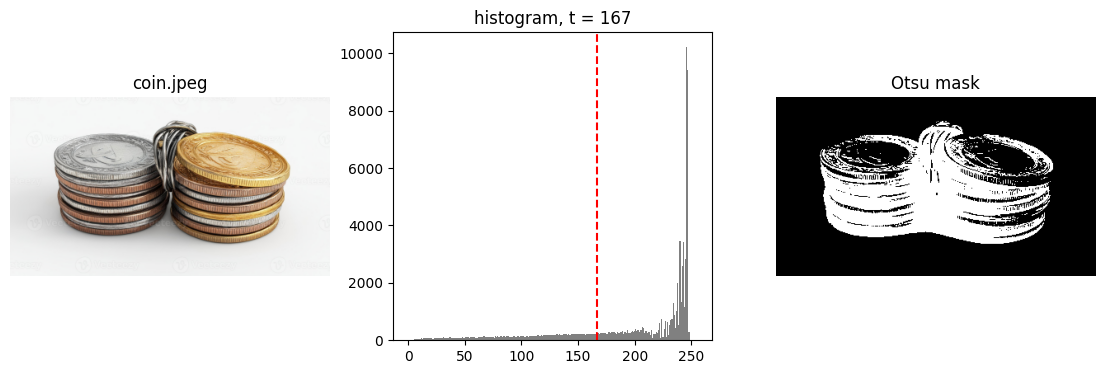

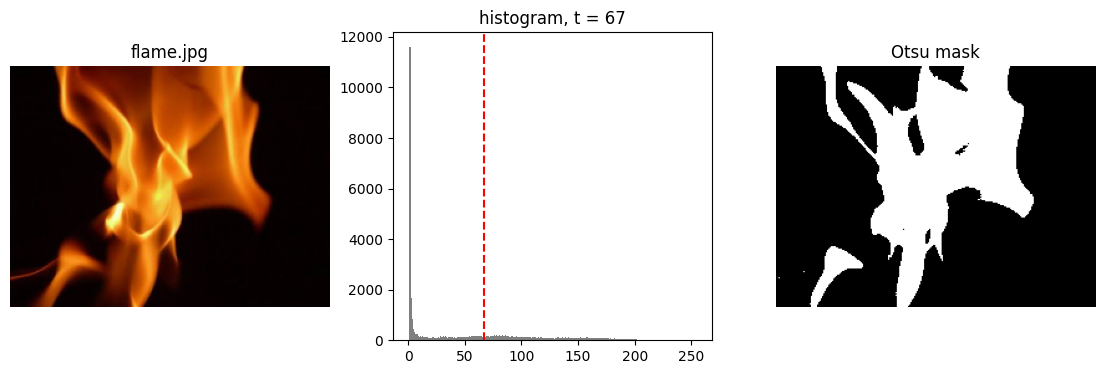

In [2]:
def otsu(gray):
    hist = np.zeros(256)
    for v in gray.ravel():
        hist[v] += 1
    p = hist / hist.sum()
    w0 = np.cumsum(p)
    mu = np.cumsum(p * np.arange(256))
    denom = w0 * (1 - w0)
    denom[denom == 0] = np.nan
    sigma = (mu[-1] * w0 - mu) ** 2 / denom
    return int(np.nanargmax(sigma)), hist

def segment(gray):
    t, hist = otsu(gray)
    b = max(2, int(0.03 * min(gray.shape)))
    border = np.concatenate([gray[:b].ravel(), gray[-b:].ravel(), gray[:, :b].ravel(), gray[:, -b:].ravel()])
    dark = border.mean() > t
    mask = gray <= t if dark else gray > t
    return mask, t, hist, dark

masks = {}
for name, (rgb, gray) in images.items():
    mask, t, hist, dark = segment(gray)
    masks[name] = mask
    fig, ax = plt.subplots(1, 3, figsize=(14, 4))
    ax[0].imshow(rgb)
    ax[0].set_title(name)
    ax[1].bar(range(256), hist, width=1.0, color="gray")
    ax[1].axvline(t, color="r", linestyle="--")
    ax[1].set_title("histogram, t = " + str(t))
    ax[2].imshow(mask, cmap="gray")
    ax[2].set_title("Otsu mask")
    ax[0].axis("off")
    ax[2].axis("off")
    plt.show()

## 2. Morphological operations

Erosion, dilation, opening (erosion then dilation) and closing (dilation then erosion).

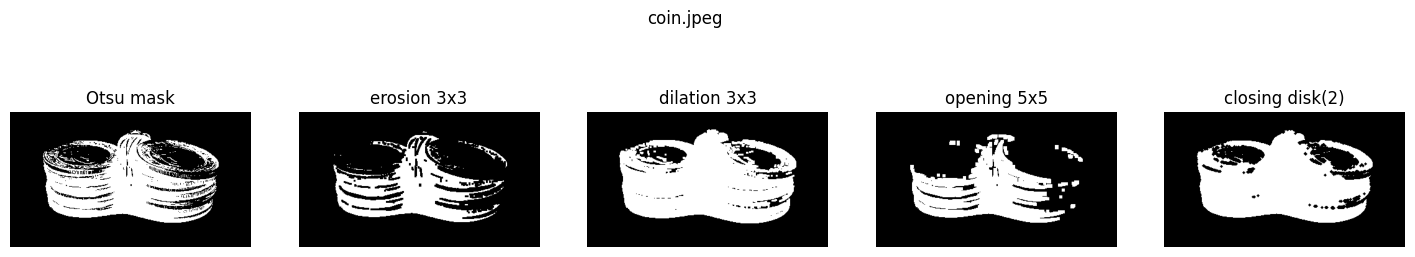

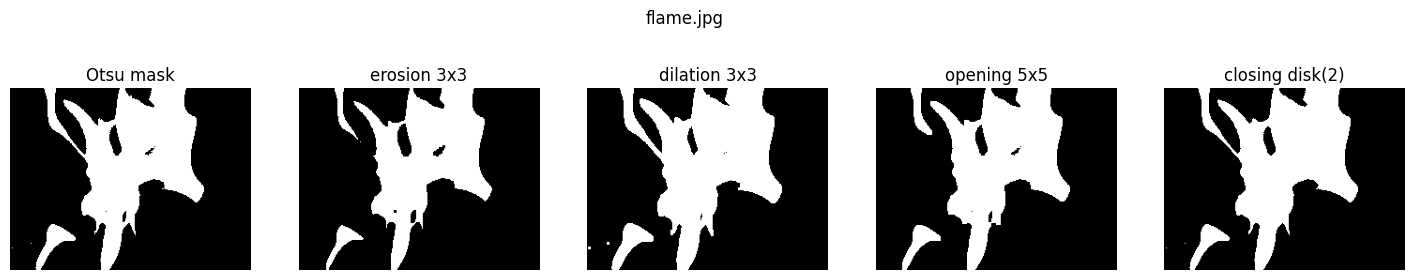

In [3]:
def square(k):
    return np.ones((k, k), dtype=bool)

def disk(r):
    y, x = np.ogrid[-r:r + 1, -r:r + 1]
    return x ** 2 + y ** 2 <= r ** 2

def shifts(img, se, pad):
    h, w = img.shape
    ch, cw = se.shape[0] // 2, se.shape[1] // 2
    p = np.pad(img, ((ch, se.shape[0] - ch - 1), (cw, se.shape[1] - cw - 1)), constant_values=pad)
    out = []
    for i in range(se.shape[0]):
        for j in range(se.shape[1]):
            if se[i, j]:
                out.append(p[i:i + h, j:j + w])
    return out

def dilation(img, se):
    result = np.zeros_like(img)
    for s in shifts(img, se[::-1, ::-1], False):
        result = result | s
    return result

def erosion(img, se):
    result = np.ones_like(img)
    for s in shifts(img, se, True):
        result = result & s
    return result

def opening(img, se):
    return dilation(erosion(img, se), se)

def closing(img, se):
    return erosion(dilation(img, se), se)

for name, mask in masks.items():
    ops = [("Otsu mask", mask),
           ("erosion 3x3", erosion(mask, square(3))),
           ("dilation 3x3", dilation(mask, square(3))),
           ("opening 5x5", opening(mask, square(5))),
           ("closing disk(2)", closing(mask, disk(2)))]
    fig, ax = plt.subplots(1, 5, figsize=(18, 3.5))
    for a, (title, m) in zip(ax, ops):
        a.imshow(m, cmap="gray")
        a.set_title(title)
        a.axis("off")
    fig.suptitle(name)
    plt.show()

## 3. Comparison: without vs with morphological processing

Closing (disk, radius 2) first to fill the holes, then opening (5x5 square) to remove the small specks.

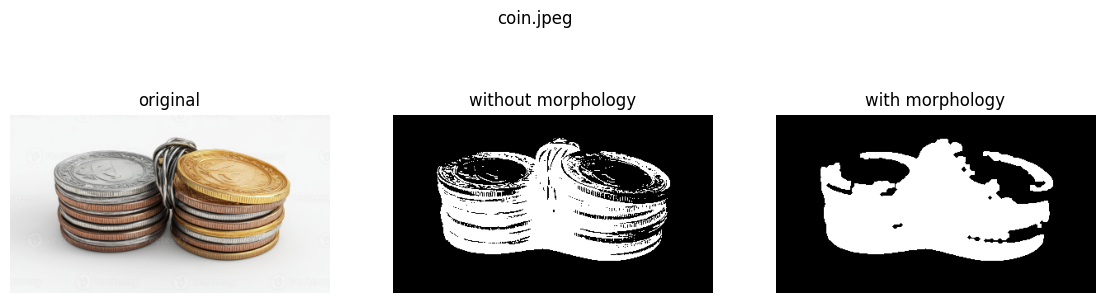

coin.jpeg
                  without   with
regions           140      2
holes             231      4
object area (%)   26.8      30.9



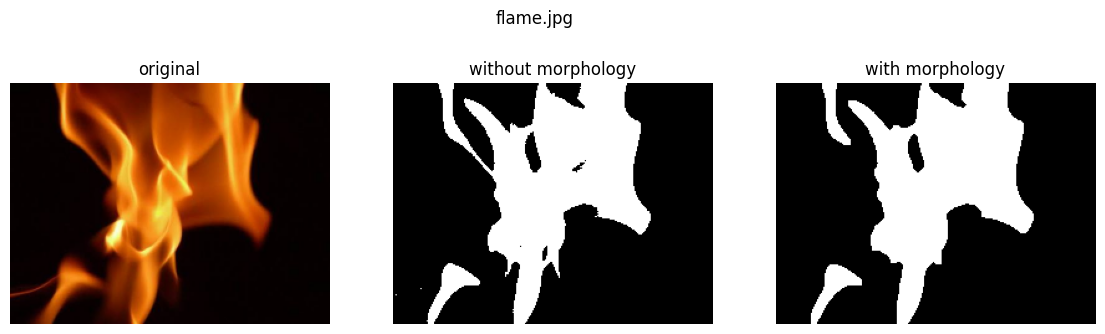

flame.jpg
                  without   with
regions           4      3
holes             8      3
object area (%)   30.0      29.8



In [4]:
def count_regions(mask):
    h, w = mask.shape
    seen = np.zeros_like(mask)
    n = 0
    for y in range(h):
        for x in range(w):
            if mask[y, x] and not seen[y, x]:
                n += 1
                seen[y, x] = True
                q = deque([(y, x)])
                while q:
                    cy, cx = q.popleft()
                    for dy in (-1, 0, 1):
                        for dx in (-1, 0, 1):
                            ny, nx = cy + dy, cx + dx
                            if 0 <= ny < h and 0 <= nx < w and mask[ny, nx] and not seen[ny, nx]:
                                seen[ny, nx] = True
                                q.append((ny, nx))
    return n

def count_holes(mask):
    return max(count_regions(~mask) - 1, 0)

for name, mask in masks.items():
    final = opening(closing(mask, disk(2)), square(5))
    rgb = images[name][0]

    fig, ax = plt.subplots(1, 3, figsize=(14, 4))
    ax[0].imshow(rgb)
    ax[0].set_title("original")
    ax[1].imshow(mask, cmap="gray")
    ax[1].set_title("without morphology")
    ax[2].imshow(final, cmap="gray")
    ax[2].set_title("with morphology")
    for a in ax:
        a.axis("off")
    fig.suptitle(name)
    plt.show()

    print(name)
    print("                  without   with")
    print("regions          ", count_regions(mask), "    ", count_regions(final))
    print("holes            ", count_holes(mask), "    ", count_holes(final))
    print("object area (%)  ", round(100 * mask.mean(), 1), "    ", round(100 * final.mean(), 1))
    print()

## Conclusion

Without morphology the Otsu mask has a lot of tiny regions and holes caused by noise and texture. After closing and opening the mask has far fewer regions and holes, so it is much cleaner. The downside is that very small or thin parts of a real object can also get removed if the structuring element is too big.